In [ ]:
### Estimate gains by fitting RNN to neural data

In [1]:
cd /Users/cl1704/PycharmProjects/embedding_dimension/BWM


/Users/cl1704/PycharmProjects/embedding_dimension/BWM


In [2]:
import pandas as pd
from matplotlib import gridspec
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import torch
import random
import string
import os
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from iblatlas.regions import BrainRegions
br = BrainRegions()
import umap
from iblatlas.regions import BrainRegions
br = BrainRegions()
from bwm_functions import *
import os
import pandas as pd
import seaborn as sns
from matplotlib import gridspec
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import matplotlib
import torch
import numpy as np
plt.rcParams["axes.grid"] = False
matplotlib.rcParams['axes.linewidth'] = .5

In [3]:
directory_path = 'Data2'
all_items = os.listdir(directory_path)
print(len(all_items))
# Filter the list to include only folders (directories)
eids = [item for item in all_items if os.path.isdir(os.path.join(directory_path, item))]

460


In [4]:
eid = eids[135]
eid = "196a2adf-ff83-49b2-823a-33f990049c2e"

In [5]:
#########################################################################
###################### Generate response matrix for eid #################
#########################################################################

full_path_to_random_folder = os.path.join(directory_path, eid)
print(f"Randomly selected eid: {full_path_to_random_folder}")

# for _ in range(1):

dim = 5
sample_size = 50
sigma = 5
n_steps = 100
threshold = .01
min_trials_per_condition = 50
conditions = ['choice']
event = "stimOn_times"
clusters = pd.read_pickle(full_path_to_random_folder + '/clusters.pkl')

clusters['cosmos'] = br.id2acronym(clusters['atlas_id'], mapping="Cosmos")

spikes = pd.read_pickle(full_path_to_random_folder + '/spikes.pkl')
trials = pd.read_pickle(full_path_to_random_folder + '/trials.pkl')

counts_series = clusters.groupby('cosmos').size()
print(counts_series)

# shape n_pseudo x n_conditions x time x n
response_matrix_train, condition_matrix_train = get_aligned_response_matrix(
spikes, clusters, trials, event, conditions,
stride=.005,
step=.005,
n_steps=n_steps,
sigma=sigma,
threshold=threshold,
min_trials_per_condition=min_trials_per_condition,regions = [item for item in counts_series.index.values if item not in ['root','void']])
#min_trials_per_condition=min_trials_per_condition,regions = ["Isocortex"])

# Restrict to active units
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .01,
                         np.std(response_matrix_train, axis=(0, 1, 2)) > .01)
response_matrix_train = response_matrix_train[
:, :, :, restriction]

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                     keepdims=True)) / np.std(z,
                                                                              axis=(0, 1),
                                                                              keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
print(response_matrix.shape)

Randomly selected eid: Data2/196a2adf-ff83-49b2-823a-33f990049c2e
cosmos
CNU          142
CTXsp        120
HPF           38
Isocortex    527
OLF           63
TH            68
root          24
void         916
dtype: int64
(200, 956)


In [6]:
data_snr = []
for neuron in range(responses.shape[2]):
    means = []
    for t in range(99):
        h = (responses[:, t + 1, neuron] - responses[:, t, neuron]) / (responses[:, t, neuron] + 10)
        means.append(np.abs(np.mean(h)))
    data_snr.append(np.mean(means))


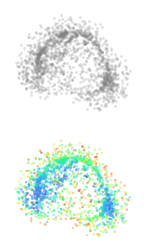

In [7]:
#########################################################################
################ Time series embedding for bwm data  ####################
#########################################################################

fig = plt.figure(figsize=(2,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(2,1)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[1,0])


##############################################################################################
######################### Strategy 1 ######################################################
# responses = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
#                                                          keepdims=True)) / np.std(response_matrix_train,
#                                                                                   axis=(0, 1, 2),
#                                                                                   keepdims=True)
# data =np.mean(np.std(responses, axis=0), axis=(0, 1))
# responses = np.mean(responses, axis=0)
# response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################
##############################################################################################


##############################################################################################
######################### Strategy 2 ######################################################

z = np.mean(response_matrix_train, axis = 0)
responses = (response_matrix_train - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)
#data_snr =np.mean(np.std(responses, axis=0), axis=(0, 1))
#data =np.log(np.mean(response_matrix_train, axis=(0, 1,2)))
responses = np.mean(responses, axis=0)
response_matrix = responses.reshape(-1, responses.shape[2])
##############################################################################################
##############################################################################################

#x_proj = TSNE(n_components = 2,perplexity = 200).fit_transform(response_matrix.T)
fit = umap.UMAP(n_components = 2,densmap = True,dens_lambda=1,n_neighbors =response_matrix.shape[1]//4)
#fit = umap.UMAP(n_components = 2,n_neighbors =response_matrix.shape[1]//4)
#x_proj = PCA().fit_transform(response_matrix.T)
x_proj= fit.fit_transform(response_matrix.T)
# import umap
# fit = umap.UMAP(densmap=True,dens_lambda =1)
# x_proj= fit.fit_transform(response_matrix.T)

sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=4,ax=ax0,legend = False,lw = 0,alpha = .25,color='gray')
sns.scatterplot(x=x_proj[:,0], y=x_proj[:,1],s=3,ax=ax1,legend = False,lw = 0,alpha = .5,hue = data_snr,palette = 'turbo')

for ax in [ax0,ax1]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_b.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)


Correlation: -0.5128
P-value: 3.9921e-118


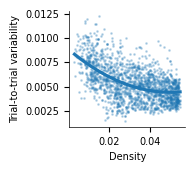

In [8]:
#########################################################################
################ Spatial density correlation for data  ##################
#########################################################################
coords = x_proj
values = np.array(data_snr)
corr, p,density,values = calculate_spatial_density_correlation(coords, values)

print(f"Correlation: {corr:.4f}")
print(f"P-value: {p:.4e}")

fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
#sns.scatterplot(x = density, y = values,ax=ax,s = 3,alpha = .5)
sns.regplot(x = density, y = values,ax=ax,scatter_kws=dict(s= 1  ,alpha = .25),order = 2)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=7, bottom=True)
ax.yaxis.set_tick_params(labelsize=7, left=True)
ax.set_xlabel("Density",fontsize=7)
ax.set_ylabel("Trial-to-trial variability",fontsize=7)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [9]:
#########################################################################
########################### Fit RNN to data  ############################
#########################################################################

condition_matrix_train = torch.tensor(condition_matrix_train).float()
condition_train = torch.mean(condition_matrix_train,dim = 0)
y_train = torch.tensor(response_matrix_train).float()
y_train = torch.mean(y_train,dim = 0)
y_train = (y_train - torch.mean(y_train, dim=(0, 1),keepdims=True)) / torch.std(y_train,dim=(0, 1),keepdims=True)

# y_train = y_train.reshape(-1,y_train.shape[2],y_train.shape[3])
# condition_train = condition_matrix_train.reshape(-1,condition_matrix_train.shape[2])
rnn = RNN(n = y_train.shape[2], input_dim = 5, n_conditions = condition_train.shape[1],beta=50,sigma_rec=0)

rnn.sigma_rec = 1
rnn.fit(steps = 100, epochs = 100000,lr = .0001, verbose = True, weight_decay = 0.,y_train =y_train ,y_test = y_train, conditions_train = condition_train, conditions_test=condition_train)

In [10]:
# Initialize RNN
rnn = RNN(n = y_train.shape[2], input_dim = 5, n_conditions = condition_train.shape[1],beta=50,sigma_rec=0)

In [12]:
rnn.sigma_rec = 1
rnn.fit(steps = 100, epochs = 100000,lr = .0001, verbose = True, weight_decay = 0.,y_train =y_train ,y_test = y_train, conditions_train = condition_train, conditions_test=condition_train)

Epoch: 10/100000............. loss: 1.1123 val_loss: 1.1056
Epoch: 20/100000............. loss: 0.7877 val_loss: 0.7974
Epoch: 30/100000............. loss: 0.5752 val_loss: 0.5718
Epoch: 40/100000............. loss: 0.4546 val_loss: 0.4535
Epoch: 50/100000............. loss: 0.3929 val_loss: 0.3932
Epoch: 60/100000............. loss: 0.3575 val_loss: 0.3563
Epoch: 70/100000............. loss: 0.3316 val_loss: 0.3342
Epoch: 80/100000............. loss: 0.3131 val_loss: 0.3136
Epoch: 90/100000............. loss: 0.2930 val_loss: 0.2972
Epoch: 100/100000............. loss: 0.2822 val_loss: 0.2758
Epoch: 110/100000............. loss: 0.2712 val_loss: 0.2714
Epoch: 120/100000............. loss: 0.2587 val_loss: 0.2556
Epoch: 130/100000............. loss: 0.2478 val_loss: 0.2447
Epoch: 140/100000............. loss: 0.2342 val_loss: 0.2394
Epoch: 150/100000............. loss: 0.2341 val_loss: 0.2312
Epoch: 160/100000............. loss: 0.2217 val_loss: 0.2238
Epoch: 170/100000............. lo

KeyboardInterrupt: 

In [121]:
torch.save(rnn,'rnn.pth')

Text(0.5, 0, 'Model')

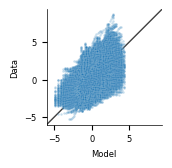

In [122]:
#################################################################################
######################### Predicted-actual plot #################################
#################################################################################
rnn.sigma_rec = 0
x =rnn.forward(condition_train, steps=100)[:,:,:rnn.n]
x = (x-torch.mean(x,dim=(0,1), keepdim=True))/torch.std(x,dim=(0,1), keepdim=True)
        # Restrict to non-input neurons
# x = rnn.observation_layer(x)
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.scatterplot(x = x.detach().flatten(), y = y_train.flatten(),ax = ax,s = 3, alpha = .25)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
lims = [
    np.min([ax.get_xlim(), ax.get_ylim()]),  # min of both axes
    np.max([ax.get_xlim(), ax.get_ylim()]),  # max of both axes
]

# now plot both limits against eachother
ax.plot(lims, lims, 'k-', alpha=0.75, zorder=0,lw=1)
ax.set_aspect('equal')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)

ax.set_ylabel("Data",size = 6)
ax.set_xlabel("Model",size = 6)

In [14]:
#################################################################################
######################### Fits #################################
#################################################################################
from sklearn.metrics import r2_score
x =rnn.forward(condition_train, steps=100)[:,:,:rnn.n]
x = (x-torch.mean(x,dim=(0,1), keepdim=True))/(torch.std(x,dim=(0,1), keepdim=True)+1e-4)
#x = rnn.observation_layer(x)
scores = []
for neuron in range(y_train.shape[2]):
    scores.append(torch.nn.MSELoss()(y_train[:,:,neuron],x[:,:,neuron].detach()).item())
sorted_neurons = np.argsort(scores)

<Axes: ylabel='Count'>

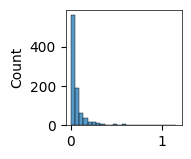

In [15]:
fig = plt.figure(figsize=(1.5,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.histplot(x = scores,ax=ax,bins = 25)

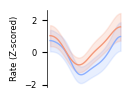

In [123]:
#############################################################
############### PSTH ########################################
#############################################################
response_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/response_matrix_train.npy' )
response_matrix_train  = response_matrix_train[:50,:]
condition_matrix_train = np.load('/Users/cl1704/PycharmProjects/embedding_dimension/BWM/condition_matrix_train.npy' )
condition_matrix_train  = condition_matrix_train[:50,:]
restriction = np.logical_and(np.std(response_matrix_train, axis=(0, 1, 2)) > .1,
                             np.std(response_matrix_train, axis=(0, 1, 2)) > .1)
response_matrix_train = response_matrix_train[
    :, :, :, restriction]


############### ******** ############
response_matrix_train = (response_matrix_train - np.mean(response_matrix_train, axis=(0, 1, 2),
                                                         keepdims=True)) / np.std(response_matrix_train,
                                                                                  axis=(0, 1, 2),
                                                                                  keepdims=True)
condition_matrix_train = torch.tensor(condition_matrix_train).float()
y_train = torch.tensor(y_train).float()
y_train = response_matrix_train.reshape(-1,response_matrix_train.shape[2],response_matrix_train.shape[3])
condition_train = condition_matrix_train.reshape(-1,condition_matrix_train.shape[2])

neuron = sorted_neurons[:rnn.n][-1]
#neuron = np.argsort( beta.detach()[:rnn.n])[0]
#neuron  = 2
#neuron = np.argsort(snr[:rnn.n])[-2]
rows = []
for condition in range(response_matrix_train.shape[1]):
    for trial in range(response_matrix_train.shape[0]):
        for t in range(response_matrix_train.shape[2]):
            rows.append({'condition': condition,
                         'trial': trial,
                         't':t,
                         'x': response_matrix_train[trial, condition, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==0], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [182]:
neuron

np.int64(79)

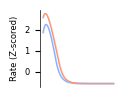

In [124]:



x =rnn.forward(condition_train, steps=100)[:,:,:rnn.n]
#x = rnn.observation_layer(x)
x = (x-torch.mean(x,dim=(0,1), keepdim=True))/torch.std(x,dim=(0,1), keepdim=True)
rows = []
for trial in range(condition_train.shape[0]):
    for t in range(response_matrix_train.shape[2]):
        rows.append({'condition': condition_train[trial,:].item(),
                         'trial': trial,
                         't':t,
                         'x': x[trial, t, neuron].item(),})
df = pd.DataFrame(rows)
fig = plt.figure(figsize=(1,1))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,1)
ax=fig.add_subplot(gs[0,0])
sns.lineplot(data = df[df.condition ==-1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[0])
sns.lineplot(data = df[df.condition ==1], x='t', y='x',errorbar = 'sd',ax=ax,legend=False,lw=1,color=sns.color_palette("coolwarm",n_colors =3)[2])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_tick_params(labelsize=6, bottom=True)
ax.yaxis.set_tick_params(labelsize=6, left=True)
ax.axes.get_xaxis().set_visible(False)
ax.axes.get_yaxis().set_visible(True)
#ax.set_ylim(-4,4)
ax.set_ylabel("Rate (Z-scored)",size = 6)
ax.set_xlabel("Time from stim",size = 6)
plt.savefig('Figures/Figure_1_2.jpg',
            format='jpeg',
            dpi=450,
            bbox_inches='tight', transparent=True)

In [459]:

#rnn = torch.load('rnn.pth',weights_only = False)

In [125]:
##################################################################
############################## SNR  ##############################
##################################################################

rnn.sigma_rec = 1
x = rnn(condition_train,100).detach()
x = (x.detach().cpu().numpy())
# x = iterative_outlier_detection(x)
response_rows = []
for trial in range(x.shape[0]):
    response_rows.append({"trial": trial,
                 'side': condition_train[trial].item(),
                 'y': x[trial, :, :],})
response_df = pd.DataFrame(response_rows)
new_df = response_df.groupby('side').y.apply(lambda x: np.stack(x)).reset_index()
response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
# response_matrix = (response_matrix - np.mean(response_matrix, axis=(0, 1, 2), keepdims=True)) / np.std(
# response_matrix, axis=(0, 1, 2), keepdims=True)

# Mean responses across trials per condition
# responses = np.mean(response_matrix, axis=1) # (n_conditions x time x neurons)
# responses = (responses - np.mean(responses, axis = (0,1))) / np.std(responses, axis = (0,1))
# responses = responses.reshape(-1, responses.shape[2]) # (n_conditions.time x neurons)

z = np.mean(response_matrix, axis = 1)
response_matrix = (response_matrix - np.mean(z, axis=(0, 1),
                                                         keepdims=True)) / np.std(z,
                                                                                  axis=(0, 1),
                                                                                  keepdims=True)


snr = []
for neuron in range(N_NEURONS):
    means= []
    for t in range(99):
        h =( response_matrix[:,0,t+1,neuron] - response_matrix[:,0,t,neuron] ) / (response_matrix[:,0,t,neuron]+5)
        means.append(np.abs(np.mean(h)))
    snr.append(np.mean(means))
snr = np.array(snr)
#snr =np.mean(np.std(response_matrix, axis=1), axis=(0, 1))

# Within condition deviation
#snr = np.mean(np.std(response_matrix, axis=1), axis=(0, 1))

In [126]:
def calculate_g(rnn,epsilon = 1,sigma=1):

    # Simulate RNN with noise
    rnn.sigma_rec = sigma
    x = rnn(condition_train,100).detach()
    x = x.detach().cpu().numpy()

    # Re-shape responses
    response_rows = []
    for trial in range(x.shape[0]):
        response_rows.append({"trial": trial,
                     'side': condition_train[trial].item(),
                     'y': x[trial, :, :],})
    response_df = pd.DataFrame(response_rows)
    new_df = response_df.groupby('side').y.apply(lambda x: np.stack(x)).reset_index()
    response_matrix = np.stack(new_df.y.values) # (n_conditions x trials_per_condition x time x n_neurons)
    z = np.mean(response_matrix, axis = 1)
    response_matrix = (response_matrix - np.mean(z, axis=(0, 1),
                                                             keepdims=True)) / np.std(z,
                                                                                      axis=(0, 1),
                                                                                      keepdims=True)
    h = np.abs(np.diff(response_matrix[:,:,:,:],axis=2)/(response_matrix[:,:,:-1,:]+epsilon))
    g = np.mean(h,axis=(0,1,2))

    return g

In [100]:
h.shape

(2, 50, 99, 930)

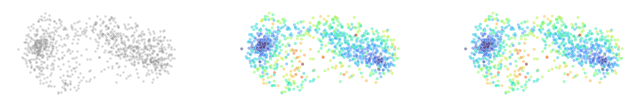

In [127]:
####################################################################
#################### CLUSTERING PLOT ###############################
####################################################################
import umap

g = calculate_g(rnn,20,1)
rnn.sigma_rec = 0

x = rnn(condition_train,100).detach()
h = rnn.recurrent_layer(x)
h = (h - torch.mean(h, dim=(0, 1), keepdim=True))

z = (x - torch.mean(x, dim=[0, 1], keepdim=True))
# dist = torch.var(z @ self.recurrent_layer.weight.t()) / torch.var(h, dim=(0, 1))

# betas = []
# for i in range(20):
#     betas.append(torch.sum(h[:,i:i+5,:] * z[:,i:i+5,:], dim=(0, 1)) / torch.sum(h[:,i:i+5,:] ** 2, dim=(0, 1)))
# beta = torch.mean(torch.stack(betas),axis=0)
beta = torch.sum(h * z, dim=(0, 1)) / torch.sum(h ** 2, dim=(0, 1))
#beta  = torch.mean(x, dim=(0, 1))
#beta = torch.linalg.norm(rnn.recurrent_layer.weight.data,dim = 1)
#x = (x - torch.mean(x,dim=(0,1)))/ torch.std(x,dim=(0,1))
x = x[:,:,:rnn.n]

x = (x - torch.mean(x,dim=(0,1)))/ (torch.std(x,dim=(0,1)))
#x = x  + 2*(2*torch.rand_like(x)-1)

x = x.detach().numpy()
#x_proj  = PCA(n_components = 2).fit_transform(responses.T)
#x_proj  = TSNE(n_components = 2,perplexity = 800).fit_transform(x.reshape(-1,x.shape[2]).T)
#x_proj  = TSNE(n_components = 2,perplexity = 200).fit_transform(responses.T)
# fit = umap.UMAP(n_components = 2,densmap=True,dens_lambda =10)
# x_proj= fit.fit_transform(x.reshape(-1,x.shape[2]).T)
fig = plt.figure(figsize=(8,3))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],s=3,ax=ax0,color='gray',alpha = .35,legend = False)
#sns.kdeplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax0,color='gray',fill = True,legend = False,levels = 20,alpha = .5)

sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax2,s=5,hue =g[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
#sns.scatterplot(x = x_proj[:,0],y = x_proj[:,1],ax=ax1,s=3,hue =mag[:x_proj.shape[0]],alpha = .5,legend = False,palette = 'turbo')
for ax in [ax0,ax1,ax2]:
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.spines['bottom'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        ax.set_aspect('equal')
plt.savefig('Figures/Figure_1_.jpg')


Text(0.5, 0, 'Noise (data)')

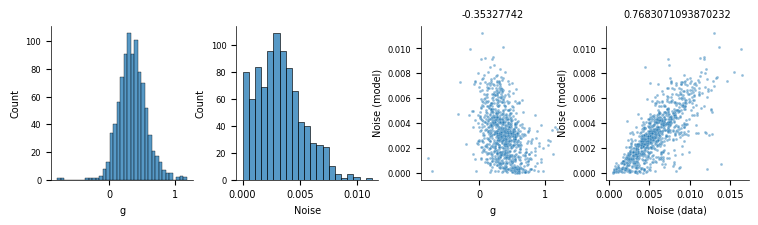

In [45]:
fig = plt.figure(figsize=(9,2))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,4,wspace = .3)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
ax3=fig.add_subplot(gs[0,3])
sns.histplot(x = beta.detach(),ax=ax0)
sns.histplot(x = snr,ax=ax1)
sns.scatterplot(y = snr[:rnn.n],x = beta.detach()[:rnn.n],ax=ax2,s=4, alpha = .5)
sns.scatterplot(y = snr[:rnn.n],x = data_snr,ax=ax3,s=4,alpha = .5)
for ax in [ax0,ax1,ax2,ax3]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.xaxis.set_tick_params(labelsize=7, bottom=True)
    ax.yaxis.set_tick_params(labelsize=6, left=True)
from scipy import stats
res1 = stats.pearsonr(snr[:rnn.n], beta.detach()[:rnn.n])
ax2.set_xlabel("g",fontsize=7)
ax2.set_ylabel("Noise (model)",fontsize=7)
ax2.set_title(str(res1[0]),fontsize=7)
ax1.set_xlabel("Noise",fontsize=7)
ax0.set_xlabel("g",fontsize=7)
ax0.set_ylabel("Count",fontsize=7)
ax1.set_ylabel("Count",fontsize=7)

res1 = stats.spearmanr( snr[:rnn.n], data_snr)
ax3.set_title(str(res1[0]),fontsize=7)

ax3.set_ylabel("Noise (model)",fontsize=7)
ax3.set_xlabel("Noise (data)",fontsize=7)
#ax2.set_xlim(0,1)

In [3585]:
#######################################################
################## Calculating gain ###################
#######################################################

AttributeError: 'int' object has no attribute 'detach'

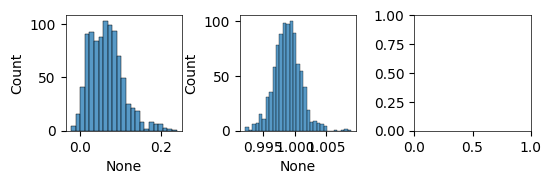

In [555]:
fig = plt.figure(figsize=(6,1.5))
from scipy.spatial import ConvexHull
gs = gridspec.GridSpec(1,3,wspace = .5)
ax0=fig.add_subplot(gs[0,0])
ax1=fig.add_subplot(gs[0,1])
ax2=fig.add_subplot(gs[0,2])
sns.histplot(x = rnn.alpha.data.detach(),ax=ax0)
sns.histplot(x = rnn.recurrent_layer.bias.data.detach(),ax=ax1)
sns.histplot(x = rnn.activation.beta.detach(),ax=ax2)
for ax in [ax0,ax1,ax2]:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.xaxis.set_tick_params(labelsize=7, bottom=True)
    ax.yaxis.set_tick_params(labelsize=7, left=True)
ax0.set_xlabel(r"$\alpha$",fontsize=7)
ax0.set_ylabel("Count",fontsize=7)